In [1]:
import sys
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

sys.path.append(os.path.abspath('..'))

from src.models import MLP
from src.train import treinar
from src.metrics import avaliar_regressao, avaliar_classificacao_multiclasse

def fixar_sementes(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Consulta os vencedores salvos no ablation
df_reg_ab = pd.read_csv('../results/ablation_regressao.csv')
df_clf_ab = pd.read_csv('../results/ablation_classificacao.csv')

print("Campeão Regressão:", df_reg_ab.iloc[0]["Experimento"], f"(RMSE: {df_reg_ab.iloc[0]['RMSE_media']:.4f})")
print("Campeão Classificação:", df_clf_ab.iloc[0]["Experimento"], f"(F1-macro: {df_clf_ab.iloc[0]['F1_macro_media']:.4f})")

# Mapa para reconstruir a configuração exata a partir do nome do experimento
mapa_configs = {
    "Baseline [32,32] ReLU Adam 1e-3": {"hidden": [32, 32], "activation": "ReLU", "dropout": 0.0, "opt": "Adam", "lr": 1e-3},
    "Arq: [16]": {"hidden": [16], "activation": "ReLU", "dropout": 0.0, "opt": "Adam", "lr": 1e-3},
    "Arq: [64, 64]": {"hidden": [64, 64], "activation": "ReLU", "dropout": 0.0, "opt": "Adam", "lr": 1e-3},
    "Arq: [128, 64, 32]": {"hidden": [128, 64, 32], "activation": "ReLU", "dropout": 0.0, "opt": "Adam", "lr": 1e-3},
    "Ativ: Tanh": {"hidden": [32, 32], "activation": "Tanh", "dropout": 0.0, "opt": "Adam", "lr": 1e-3},
    "Ativ: GELU": {"hidden": [32, 32], "activation": "GELU", "dropout": 0.0, "opt": "Adam", "lr": 1e-3},
    "Dropout: 0.2": {"hidden": [32, 32], "activation": "ReLU", "dropout": 0.2, "opt": "Adam", "lr": 1e-3},
    "Dropout: 0.4": {"hidden": [32, 32], "activation": "ReLU", "dropout": 0.4, "opt": "Adam", "lr": 1e-3},
    "LR: 1e-2 (Adam)": {"hidden": [32, 32], "activation": "ReLU", "dropout": 0.0, "opt": "Adam", "lr": 1e-2},
    "LR: 1e-4 (Adam)": {"hidden": [32, 32], "activation": "ReLU", "dropout": 0.0, "opt": "Adam", "lr": 1e-4},
    "Opt: SGD (lr=1e-2)": {"hidden": [32, 32], "activation": "ReLU", "dropout": 0.0, "opt": "SGD", "lr": 1e-2},
}

cfg_reg_win = mapa_configs[df_reg_ab.iloc[0]["Experimento"]]
cfg_clf_win = mapa_configs[df_clf_ab.iloc[0]["Experimento"]]

Campeão Regressão: Dropout: 0.2 (RMSE: 0.4941)
Campeão Classificação: Ativ: Tanh (F1-macro: 0.7664)


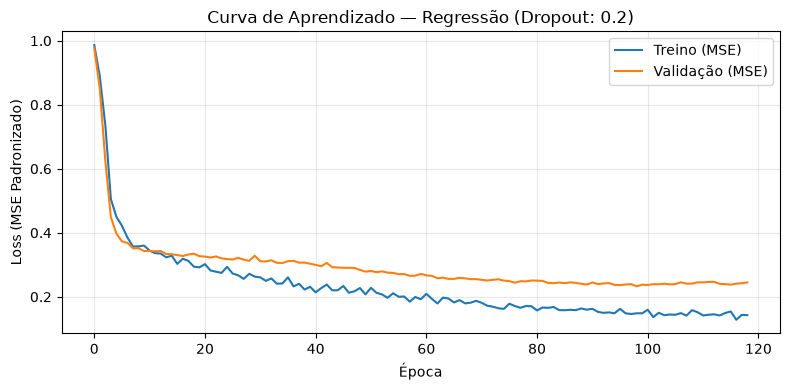

In [6]:
target_reg = 'Mental_Wellbeing_Score'
df_tr = pd.read_csv('../data/processed/train_regression.csv')
df_te = pd.read_csv('../data/processed/test_regression.csv')

features_reg = df_tr.drop(columns=[target_reg]).columns.tolist()
X_full, y_full = df_tr[features_reg].values, df_tr[target_reg].values
X_test, y_test = df_te[features_reg].values, df_te[target_reg].values

X_train, X_val, y_train, y_val = train_test_split(X_full, y_full, test_size=0.2, random_state=42)

sc_X = StandardScaler().fit(X_train)
sc_y = StandardScaler().fit(y_train.reshape(-1, 1))

X_tr_t = torch.tensor(sc_X.transform(X_train), dtype=torch.float32)
y_tr_t = torch.tensor(sc_y.transform(y_train.reshape(-1, 1)), dtype=torch.float32)
X_va_t = torch.tensor(sc_X.transform(X_val), dtype=torch.float32)
y_va_t = torch.tensor(sc_y.transform(y_val.reshape(-1, 1)), dtype=torch.float32)
X_te_t_reg = torch.tensor(sc_X.transform(X_test), dtype=torch.float32)

dl_tr = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=32, shuffle=True)
dl_va = DataLoader(TensorDataset(X_va_t, y_va_t), batch_size=32, shuffle=False)

fixar_sementes(42)
arq_reg = {"in_dim": X_train.shape[1], "out_dim": 1, "hidden": cfg_reg_win["hidden"],
           "activation": cfg_reg_win["activation"], "dropout": cfg_reg_win["dropout"]}
modelo_reg = MLP(**arq_reg)
otim_reg = torch.optim.Adam(modelo_reg.parameters(), lr=cfg_reg_win["lr"]) if cfg_reg_win["opt"] == "Adam" else torch.optim.SGD(modelo_reg.parameters(), lr=cfg_reg_win["lr"], momentum=0.9)

hist_reg = treinar(modelo_reg, dl_tr, dl_va, nn.MSELoss(), otim_reg, n_epocas=200, paciencia=20)

# Salva checkpoint final
torch.save({
    "task": "regression",
    "state_dict": modelo_reg.state_dict(),
    "config": arq_reg,
    "features": features_reg,
    "x_media": torch.tensor(sc_X.mean_, dtype=torch.float32),
    "x_desvio": torch.tensor(sc_X.scale_, dtype=torch.float32),
    "y_media": float(sc_y.mean_[0]),
    "y_desvio": float(sc_y.scale_[0])
}, '../models/modelo_regressao.pt')

# Curva de aprendizado
plt.figure(figsize=(8, 4))
plt.plot(hist_reg["treino"], label="Treino (MSE)")
plt.plot(hist_reg["val"], label="Validação (MSE)")
plt.title(f"Curva de Aprendizado — Regressão ({df_reg_ab.iloc[0]['Experimento']})")
plt.xlabel("Época")
plt.ylabel("Loss (MSE Padronizado)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../results/curva_regressao.png', dpi=150)
plt.show()

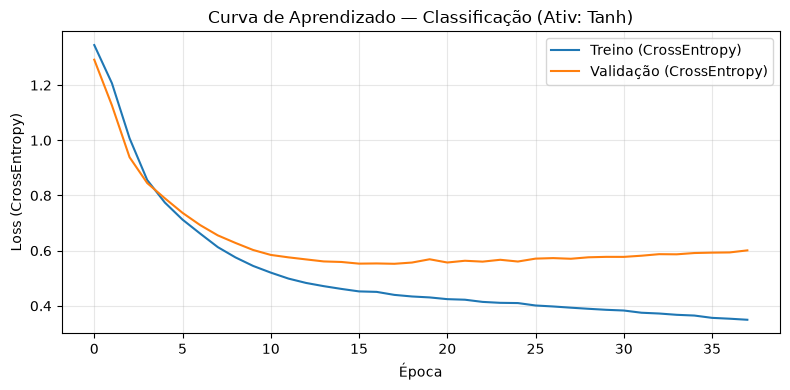

In [3]:
target_clf = 'Addiction_Level'
df_tr = pd.read_csv('../data/processed/train_classification.csv')
df_te = pd.read_csv('../data/processed/test_classification.csv')

features_clf = df_tr.drop(columns=[target_clf]).columns.tolist()
X_full, y_full = df_tr[features_clf].values, df_tr[target_clf].values
X_test, y_test = df_te[features_clf].values, df_te[target_clf].values

X_train, X_val, y_train, y_val = train_test_split(X_full, y_full, test_size=0.2, random_state=42, stratify=y_full)

sc_X_clf = StandardScaler().fit(X_train)
X_tr_t = torch.tensor(sc_X_clf.transform(X_train), dtype=torch.float32)
y_tr_t = torch.tensor(y_train, dtype=torch.long)
X_va_t = torch.tensor(sc_X_clf.transform(X_val), dtype=torch.float32)
y_va_t = torch.tensor(y_val, dtype=torch.long)
X_te_t_clf = torch.tensor(sc_X_clf.transform(X_test), dtype=torch.float32)

dl_tr = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=32, shuffle=True)
dl_va = DataLoader(TensorDataset(X_va_t, y_va_t), batch_size=32, shuffle=False)

fixar_sementes(42)
arq_clf = {"in_dim": X_train.shape[1], "out_dim": 4, "hidden": cfg_clf_win["hidden"],
           "activation": cfg_clf_win["activation"], "dropout": cfg_clf_win["dropout"]}
modelo_clf = MLP(**arq_clf)
otim_clf = torch.optim.Adam(modelo_clf.parameters(), lr=cfg_clf_win["lr"]) if cfg_clf_win["opt"] == "Adam" else torch.optim.SGD(modelo_clf.parameters(), lr=cfg_clf_win["lr"], momentum=0.9)

hist_clf = treinar(modelo_clf, dl_tr, dl_va, nn.CrossEntropyLoss(), otim_clf, n_epocas=200, paciencia=20)

# Salva checkpoint final
torch.save({
    "task": "classification",
    "state_dict": modelo_clf.state_dict(),
    "config": arq_clf,
    "features": features_clf,
    "x_media": torch.tensor(sc_X_clf.mean_, dtype=torch.float32),
    "x_desvio": torch.tensor(sc_X_clf.scale_, dtype=torch.float32)
}, '../models/modelo_classificacao.pt')

# Curva de aprendizado
plt.figure(figsize=(8, 4))
plt.plot(hist_clf["treino"], label="Treino (CrossEntropy)")
plt.plot(hist_clf["val"], label="Validação (CrossEntropy)")
plt.title(f"Curva de Aprendizado — Classificação ({df_clf_ab.iloc[0]['Experimento']})")
plt.xlabel("Época")
plt.ylabel("Loss (CrossEntropy)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../results/curva_classificacao.png', dpi=150)
plt.show()

In [4]:
def medir_latencia(modelo, x_exemplo, n_reps=1000):
    modelo.eval()
    # Warm-up
    with torch.inference_mode():
        for _ in range(50):
            _ = modelo(x_exemplo)
    
    t0 = time.perf_counter()
    with torch.inference_mode():
        for _ in range(n_reps):
            _ = modelo(x_exemplo)
    dt = (time.perf_counter() - t0) / n_reps
    return dt * 1000  # em milissegundos

profiling_rows = []
for nome, mod, arq_path, X_te in [
    ("MLP Regressão (Campeão)", modelo_reg, "../models/modelo_regressao.pt", X_te_t_reg),
    ("MLP Classificação (Campeão)", modelo_clf, "../models/modelo_classificacao.pt", X_te_t_clf),
]:
    n_params = sum(p.numel() for p in mod.parameters() if p.requires_grad)
    tamanho_kb = os.path.getsize(arq_path) / 1024
    lat_1 = medir_latencia(mod, X_te[:1])
    lat_32 = medir_latencia(mod, X_te[:32])
    profiling_rows.append({
        "Modelo": nome,
        "Parâmetros": n_params,
        "Tamanho_disco_KB": round(tamanho_kb, 2),
        "Latência_1_amostra_ms": round(lat_1, 4),
        "Latência_batch32_ms": round(lat_32, 4),
    })

df_prof = pd.DataFrame(profiling_rows)
df_prof.to_csv('../results/profiling_modelos.csv', index=False)
display(df_prof)

,Modelo,Parâmetros,Tamanho_disco_KB,Latência_1_amostra_ms,Latência_batch32_ms
0,MLP Regressão (Campeão),2049,12.89,0.2876,0.2189
1,MLP Classificação (Campeão),2148,13.19,0.4098,0.3873


In [7]:
# Executa o script de inferência diretamente como linha de comando (exigência do projeto)
!python ../src/inference.py --modelo ../models/modelo_regressao.pt --entrada ../data/processed/test_regression.csv
print("-" * 60)
!python ../src/inference.py --modelo ../models/modelo_classificacao.pt --entrada ../data/processed/test_classification.csv

Inferência concluída para 300 amostras.
Primeiras 10 previsões: [-0.4704157  -0.3783363   0.15522394 -0.6696954  -1.2497089   0.42692095
  0.73068005 -1.449152   -1.2324828  -1.2064219 ]
------------------------------------------------------------
Inferência concluída para 300 amostras.
Primeiras 10 previsões: [1 2 2 0 3 0 3 0 1 3]
